# HW1 Part D: SEIR model with births and deaths

$$
\begin{aligned}
\frac{dS}{dt} &= \mu N - \beta S I - \mu S \\
\frac{dE}{dt} &= \beta S I - (\sigma + \mu) E \\
\frac{dI}{dt} &= \sigma E - (\gamma + \mu) I \\
\frac{dR}{dt} &= \gamma I - \mu R
\end{aligned}
$$

- $E$: exposed (infected but not yet infectious); $1/\sigma$ is the mean latent period
- $\mu$: birth and death rate

Simulate for 365 and 1500 days with $N = 2000$, $S(0) = 1980$, $E(0) = 15$, $I(0) = 5$, $R(0) = 0$, and $\beta = 0.125 \times 10^{-3}$, $\gamma = 0.1$, $\sigma = 0.25$, $\mu = 0.005$ (all per day).

- Plot the compartments; describe the epidemic waves (timing and size of each).
- Compute

$$R_0 = \frac{\beta N \sigma}{(\sigma + \mu)(\gamma + \mu)}$$

  and compare with Part C. Compare the long-term $S$ with $N / R_0$.
- Discuss the effect of the exposed compartment and of $\mu$ (note $\mu = 0.005$ is a 200-day lifespan, chosen to make the waves visible).


In [1]:
import numpy as np

def forwardEuler(f, y0, t):
    # array of 0's to store inital value and all subsequent solved values
    y = np.zeros((len(t),) + np.shape(y0))
    # add initial condition to beginning of the array
    y[0] = y0
    # iterate over each time step
    for i in range(1, len(t)):
        #compute change in time 
        dt = t[i] - t[i-1]
        #previous time step solution plus time step change
        # multiplied by the derivative at the previous time step
        y[i] = y[i-1] + dt * f(y[i-1], t[i-1])
    return y


def seir_ders(y, beta, gamma, sigma, mu, N):

    S, E, I, R = y
    dSdt = mu*N - beta * S * I - mu*S
    dEdt = beta * S * I - (sigma+mu )*E
    dIdt = sigma * E - (gamma + mu) * I
    dRdt = gamma * I - mu*R
    return np.array([dSdt, dEdt, dIdt, dRdt])

def seir_model(y0, t, beta, gamma, sigma, mu, N):
    def f(y, t):
        return seir_ders(y, beta, gamma, sigma, mu, N)
    return forwardEuler(f, y0, t)


S+E+I+R min/max over 1500 days: 2000.0 2000.0


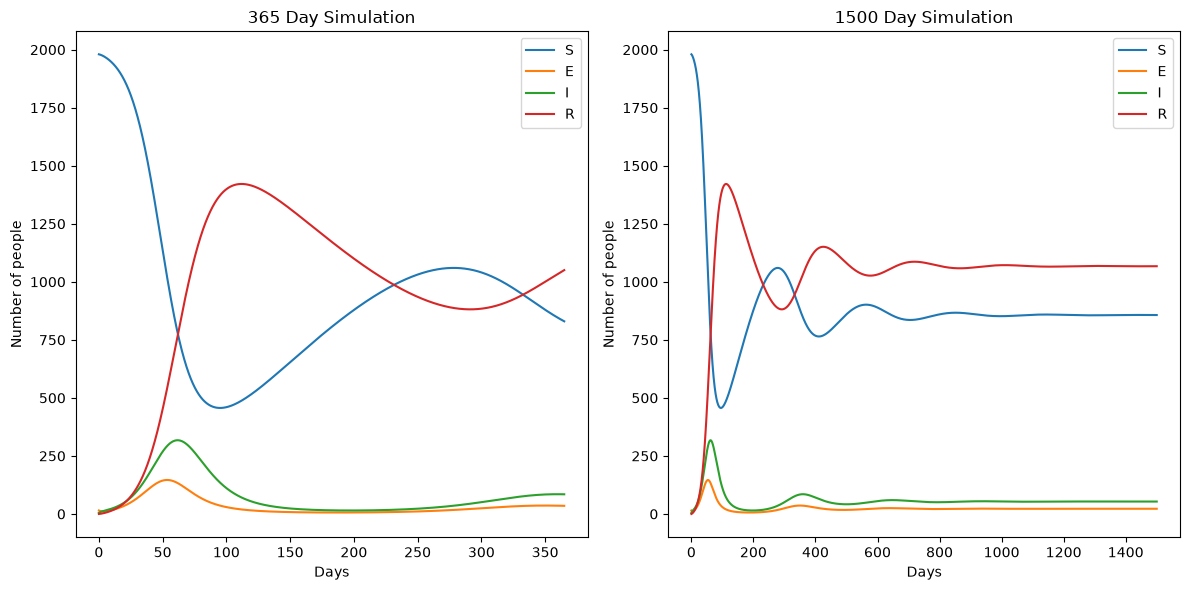

In [2]:
# parameters (all per day)
beta = 0.000125
gamma = 0.1
sigma = 0.25
mu = 0.005


N = 2000
S0 = 1980   
E0 = 15
I0 = 5
R0 = 0
y0 = np.array([S0, E0, I0, R0])

# 365 days simulation, euler step of 0.1 day (see part A for why not 1 day)
t_short = np.arange(0, 365.1, 0.1)

y = seir_model(y0, t_short, beta, gamma, sigma, mu, N)    

# 1500 days simulation 
t_long = np.arange(0, 1500.1, 0.1)
y_long = seir_model(y0, t_long, beta, gamma, sigma, mu, N)

# check the population stays at N (births = deaths)
print("S+E+I+R min/max over 1500 days:", y_long.sum(axis=1).min().round(6), y_long.sum(axis=1).max().round(6))

# Plot the results for both simulations
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(t_short, y[:, 0], label='S')
plt.plot(t_short, y[:, 1], label='E')
plt.plot(t_short, y[:, 2], label='I')
plt.plot(t_short, y[:, 3], label='R')
plt.title('365 Day Simulation')
plt.xlabel('Days')
plt.ylabel('Number of people')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(t_long, y_long[:, 0], label='S')
plt.plot(t_long, y_long[:, 1], label='E')
plt.plot(t_long, y_long[:, 2], label='I')
plt.plot(t_long, y_long[:, 3], label='R')
plt.title('1500 Day Simulation')
plt.xlabel('Days')
plt.ylabel('Number of people')
plt.legend()

plt.tight_layout()
plt.savefig('partD_seir.png', dpi=150, bbox_inches='tight')
plt.show()

365 Days Simulation:
Wave 1:  peak on day 61.7 with 317.6 infected
Wave 2:  peak on day 359.4 with 85.1 infected
  trough after wave 1: day 197.5, 15.0 infected
  days between peaks: [297.7]

1500 Days Simulation:
Wave 1:  peak on day 61.7 with 317.6 infected
Wave 2:  peak on day 359.4 with 85.1 infected
Wave 3:  peak on day 648.0 with 59.7 infected
Wave 4:  peak on day 937.8 with 54.8 infected
Wave 5:  peak on day 1227.9 with 53.7 infected
  trough after wave 1: day 197.5, 15.0 infected
  trough after wave 2: day 500.1, 41.7 infected
  trough after wave 3: day 792.0, 50.5 infected
  trough after wave 4: day 1082.7, 52.7 infected
  trough after wave 5: day 1373.0, 53.2 infected
  days between peaks: [297.7 288.6 289.8 290.1]

S: minimum 456.7 on day 95.1;  S at day 365 = 829.8;  S at day 1500 = 856.9
I at day 1500 = 53.4,  E at day 1500 = 22.4


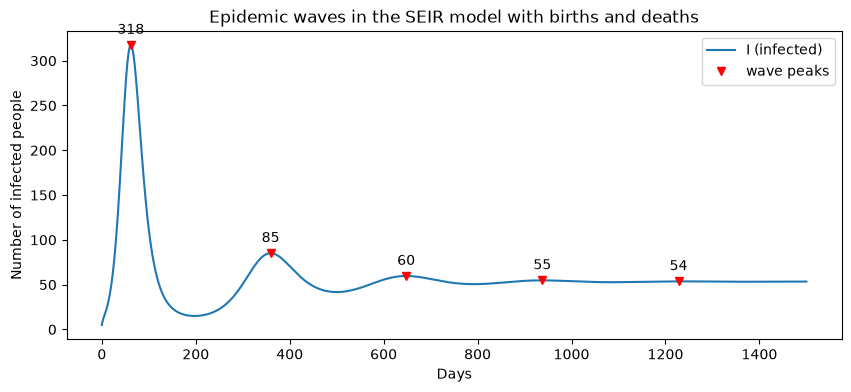

In [3]:
# report the timing and size of each wave (local maxima of I) and the troughs between them
def report_waves(t, y):
    I = y[:, 2]
    # a peak is where the slope of I changes from + to -, a trough where it changes from - to +
    peaks = (np.diff(np.sign(np.diff(I))) < 0).nonzero()[0] + 1
    troughs = (np.diff(np.sign(np.diff(I))) > 0).nonzero()[0] + 1
    for i, peak in enumerate(peaks):
        print(f"Wave {i+1}:  peak on day {t[peak]:.1f} with {I[peak]:.1f} infected")
    for i, tr in enumerate(troughs):
        print(f"  trough after wave {i+1}: day {t[tr]:.1f}, {I[tr]:.1f} infected")
    if len(peaks) > 1:
        print("  days between peaks:", np.diff(t[peaks]).round(1))
    return peaks

print("365 Days Simulation:")
peaks_365 = report_waves(t_short, y)

print("\n1500 Days Simulation:")
peaks_long = report_waves(t_long, y_long)

S_long = y_long[:, 0]
print(f"\nS: minimum {S_long.min():.1f} on day {t_long[S_long.argmin()]:.1f};  S at day 365 = {y[-1, 0]:.1f};  S at day 1500 = {S_long[-1]:.1f}")
print(f"I at day 1500 = {y_long[-1, 2]:.1f},  E at day 1500 = {y_long[-1, 1]:.1f}")

# I alone over 1500 days with the peaks marked, so the waves are easy to see
plt.figure(figsize=(10, 4))
plt.plot(t_long, y_long[:, 2], label='I (infected)')
plt.plot(t_long[peaks_long], y_long[peaks_long, 2], 'rv', label='wave peaks')
for p in peaks_long:
    plt.annotate(f'{y_long[p, 2]:.0f}', (t_long[p], y_long[p, 2]), textcoords='offset points', xytext=(0, 8), ha='center')
plt.xlabel('Days')
plt.ylabel('Number of infected people')
plt.title('Epidemic waves in the SEIR model with births and deaths')
plt.legend()
plt.savefig('partD_waves.png', dpi=150, bbox_inches='tight')
plt.show()

D.iii

In the first 365 days there are two waves, the first peaking at about 318 infected on day 62 and the second at about 85 on day 359, with a trough of about 15 infected around day 198 in between. Over 1500 days there are five waves on days 62, 359, 648, 938 and 1228 with peaks of 318, 85, 60, 55 and 54 infected, about 290 days apart, with each wave smaller than the last and the troughs rising (15, 42, 51, 53, 53) until I settles at about 53 infected. The waves are caused by births adding mu*N = 10 new susceptible people per day. After the first wave infects most of S, I falls since each infected person infects fewer than one other, but births slowly refill S until it is back above N/R0 and each case more than replaces itself, which starts the next wave. The waves shrink because S never gets back to its starting value, and eventually births and infections balance out at a steady level, which is why the waves attenuate toward about 53 infected rather than to 0. This is one reason why some diseases (epidemics) still exist. 

In [4]:
R0_seir = beta * N * sigma / ((gamma + mu) * (sigma + mu))
R0_sir = beta * N / gamma   # part C
print(f"SEIR R0: {R0_seir:.3f}      SIR R0 from part C: {R0_sir:.3f}")
# the two correction factors: surviving the latent period, and recovery vs death during the infectious period
print(f"sigma/(sigma+mu) = {sigma/(sigma+mu):.3f},  gamma/(gamma+mu) = {gamma/(gamma+mu):.3f},  product x 2.5 = {R0_sir * sigma/(sigma+mu) * gamma/(gamma+mu):.3f}")

# long-term susceptible population vs N/R0
print(f"\nN/R0 = {N / R0_seir:.1f}      S at day 1500 = {y_long[-1, 0]:.1f}")

# endemic equilibrium from setting all four derivatives to zero:
#   S* = N/R0,  I* = mu*(N - S*)/(beta*S*),  E* = (gamma+mu)*I*/sigma,  R* = gamma*I*/mu
S_eq = N / R0_seir
I_eq = mu * (N - S_eq) / (beta * S_eq)
E_eq = (gamma + mu) * I_eq / sigma
R_eq = gamma * I_eq / mu
print(f"equilibrium:  S* = {S_eq:.1f}, E* = {E_eq:.1f}, I* = {I_eq:.1f}, R* = {R_eq:.1f}")
print(f"simulation at day 1500:  S = {y_long[-1,0]:.1f}, E = {y_long[-1,1]:.1f}, I = {y_long[-1,2]:.1f}, R = {y_long[-1,3]:.1f}")

SEIR R0: 2.334      SIR R0 from part C: 2.500
sigma/(sigma+mu) = 0.980,  gamma/(gamma+mu) = 0.952,  product x 2.5 = 2.334

N/R0 = 856.8      S at day 1500 = 856.9
equilibrium:  S* = 856.8, E* = 22.4, I* = 53.4, R* = 1067.4
simulation at day 1500:  S = 856.9, E = 22.4, I = 53.4, R = 1067.2


D.iv

R0 = beta*N*sigma/((sigma+mu)*(gamma+mu)) = 2.33, compared to 2.5 in part C. It is lower because deaths now remove people from the chain of infection. An exposed person can die before becoming infectious (sigma/(sigma+mu) = 0.98 survive the latent period) and an infectious person leaves by recovery or death so the average infectious period is 1/(gamma+mu) = 9.5 days instead of 10 (a factor of gamma/(gamma+mu) = 0.952), and 2.5*0.98*0.952 = 2.33. N/R0 = 857 and the simulated S at day 1500 is 857, so the long term susceptible population is N/R0. This is the number of susceptible people at which each infected person infects exactly one other person, so I neither grows nor shrinks, the same idea as S = gamma/beta = 800 at the peak in part C. Births push S up toward it when S is below it and infections pull S down when S is above it, so the population settles there.

SEIR, μ = 0.005 (part D):
   peaks on days [  61.7  359.4  648.   937.8 1227.9] with [317.6  85.1  59.7  54.8  53.7] infected
SIR with births/deaths, μ = 0.005 (no E; the 15 exposed start as infected):
   peaks on days [  34.2  288.3  527.   765.8 1004.8 1243.9 1483. ] with [462.8  99.9  64.4  57.4  55.7  55.4  55.3] infected
SEIR, μ = 0 (no births or deaths):
   peaks on days [58.4] with [336.2] infected
SEIR, μ = 1/(75 years) (realistic):
   peaks on days [58.4] with [336.1] infected


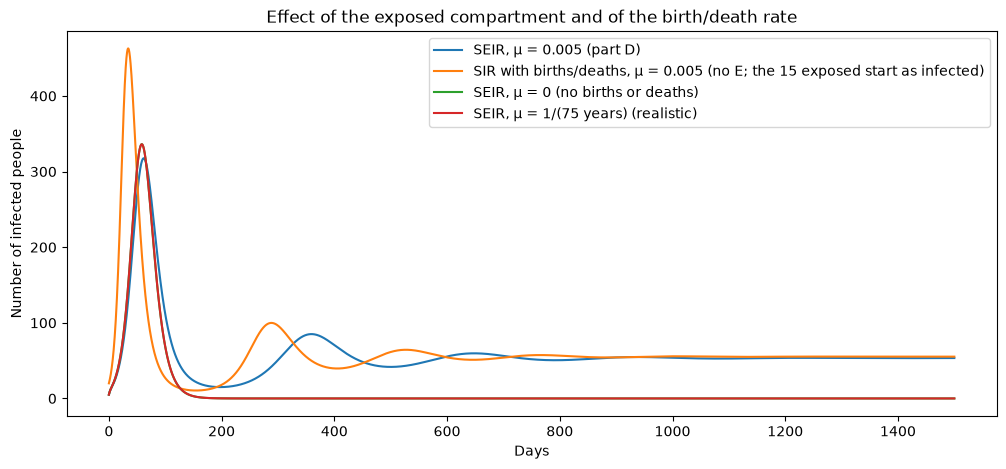

R0 with realistic mu: 2.499


In [5]:
def sir_bd_ders(y, beta, gamma, mu, N):
    # SIR with births and deaths (no exposed compartment)
    S, I, R = y
    dSdt = mu*N - beta * S * I - mu*S
    dIdt = beta * S * I - (gamma + mu) * I
    dRdt = gamma * I - mu*R
    return np.array([dSdt, dIdt, dRdt])

mu_real = 1 / (75 * 365)   # 75 year lifespan

cases = {
    'SEIR, μ = 0.005 (part D)': seir_model(y0, t_long, beta, gamma, sigma, mu, N)[:, 2],
    'SIR with births/deaths, μ = 0.005 (no E; the 15 exposed start as infected)':
        forwardEuler(lambda y, t: sir_bd_ders(y, beta, gamma, mu, N), np.array([S0, E0 + I0, 0]), t_long)[:, 1],
    'SEIR, μ = 0 (no births or deaths)': seir_model(y0, t_long, beta, gamma, sigma, 0.0, N)[:, 2],
    'SEIR, μ = 1/(75 years) (realistic)': seir_model(y0, t_long, beta, gamma, sigma, mu_real, N)[:, 2],
}

plt.figure(figsize=(12, 5))
for label, I_case in cases.items():
    plt.plot(t_long, I_case, label=label)
    peaks = (np.diff(np.sign(np.diff(I_case))) < 0).nonzero()[0] + 1
    print(f"{label}:")
    print("   peaks on days", t_long[peaks].round(1), "with", I_case[peaks].round(1), "infected")
plt.xlabel('Days')
plt.ylabel('Number of infected people')
plt.title('Effect of the exposed compartment and of the birth/death rate')
plt.legend()
plt.savefig('partD_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"R0 with realistic mu: {beta * N * sigma / ((gamma + mu_real) * (sigma + mu_real)):.3f}")

D.v

The exposed compartment adds a 1/sigma = 4 day delay between being infected and being infectious. Without it (SIR with births and deaths) the first wave peaks on day 34 with about 463 infected instead of day 62 with about 318, so the exposed compartment delays the first peak by about four weeks and lowers it by about 30%, because people in E are not transmitting yet, which slows the spread and gives more people time to recover before the peak. The birth and death rate is what allows the repeated waves. With mu = 0 the model behaves like part C, one wave peaking at about 336 on day 58 and then the disease dies out with S stuck at about 211. mu = 0.005 is a 200 day lifespan, chosen so the waves fit in a short simulation. With a realistic 75 year lifespan (mu about 0.00004 per day, about 0.07 births per day instead of 10) R0 goes back to 2.5, the first wave looks the same as mu = 0, and no second wave shows up in 1500 days since it would take decades for births to bring S back up to N/R0, and by then I is essentially 0 so the disease would have to be reintroduced from outside.